In [1]:
# Imports
import torch
import torchvision
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader

import os
import random 
import matplotlib.pyplot as plt
from collections import defaultdict

# **1. Assembling the joint dataset**

In [2]:
transform = T.ToTensor() # Converts to Torch Tensor (C, H, W) so it can be later trained on

mnist = torchvision.datasets.MNIST(root='./data', download=True, transform=transform)  # Note this is only the 'training' data
svhn = torchvision.datasets.SVHN(root='./data', download=True, transform=transform)    # Note this is only the 'training' data

print(len(mnist))
print(len(svhn))

60000
73257


Get the indices per label of each dataset.

In [3]:
mnist_indices = defaultdict(list)
svhn_indices = defaultdict(list)

for i, label in enumerate(mnist.targets):
    mnist_indices[int(label)].append(i)

for i, label in enumerate(svhn.labels):
    svhn_indices[label].append(i)

print(mnist_indices[0])
print(svhn_indices[0])

[1, 21, 34, 37, 51, 56, 63, 68, 69, 75, 81, 88, 95, 108, 114, 118, 119, 121, 156, 169, 192, 206, 209, 210, 216, 229, 232, 234, 246, 249, 260, 283, 293, 296, 303, 320, 326, 359, 399, 427, 429, 435, 440, 451, 453, 458, 462, 464, 473, 489, 519, 524, 526, 527, 542, 577, 582, 596, 603, 612, 633, 639, 656, 662, 666, 667, 668, 669, 689, 702, 709, 712, 733, 743, 745, 776, 781, 787, 790, 818, 825, 849, 859, 860, 869, 872, 889, 903, 927, 943, 949, 952, 957, 965, 979, 984, 997, 1000, 1015, 1018, 1028, 1029, 1040, 1046, 1049, 1076, 1078, 1090, 1093, 1102, 1107, 1128, 1137, 1152, 1168, 1179, 1195, 1209, 1268, 1304, 1310, 1346, 1349, 1359, 1363, 1367, 1368, 1371, 1372, 1377, 1386, 1387, 1403, 1423, 1443, 1454, 1471, 1479, 1489, 1495, 1501, 1502, 1512, 1517, 1530, 1532, 1571, 1578, 1590, 1596, 1600, 1605, 1606, 1625, 1626, 1645, 1664, 1678, 1682, 1701, 1709, 1712, 1723, 1725, 1729, 1742, 1769, 1771, 1775, 1796, 1797, 1798, 1819, 1828, 1837, 1857, 1868, 1876, 1877, 1897, 1904, 1907, 1916, 1926, 1927, 

Calculating the number of pairs per number.

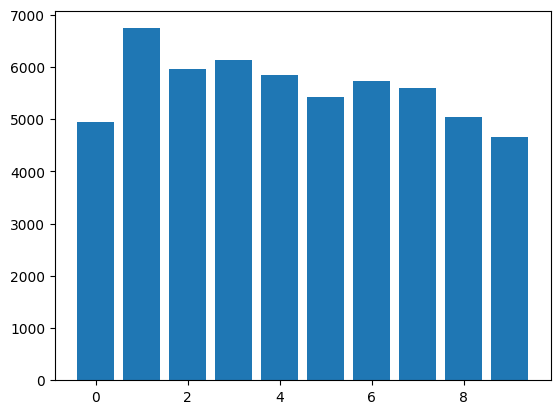

In [4]:
n_pairs = {
    digit: min(len(mnist_indices[digit]), len(svhn_indices[digit]))
    for digit in range(10)
}

plt.bar(n_pairs.keys(), n_pairs.values())
plt.show()

We decided not to balance the classes so far, since there are no big differences. Now we combine the datasets into tuples of indexes and their shared label.

In [5]:
pairs = []

for digit in range(10):
    mnist_idx = mnist_indices[digit].copy()
    svhn_idx = svhn_indices[digit].copy()

    # Shuffle to avoid bias
    random.shuffle(mnist_idx)
    random.shuffle(svhn_idx)

    n = n_pairs[digit]

    for mnist_idx, svhn_idx in zip(mnist_idx[:n], svhn_idx[:n]):
        pairs.append((mnist_idx, svhn_idx, digit))

print(pairs)

[(34051, 24678, 0), (41880, 63096, 0), (2557, 6658, 0), (54609, 32889, 0), (33645, 60982, 0), (15318, 66403, 0), (9055, 42977, 0), (9675, 72100, 0), (30340, 42375, 0), (49459, 37026, 0), (20681, 31314, 0), (6538, 47980, 0), (27749, 55070, 0), (33136, 56771, 0), (32880, 24638, 0), (42185, 44358, 0), (8134, 36526, 0), (38926, 46942, 0), (57700, 45990, 0), (8509, 55402, 0), (14425, 8223, 0), (45953, 7965, 0), (43195, 45428, 0), (14097, 13376, 0), (59972, 36008, 0), (30929, 68775, 0), (28317, 39463, 0), (54549, 30353, 0), (16803, 22487, 0), (53073, 49809, 0), (51331, 55174, 0), (31604, 4490, 0), (27466, 11052, 0), (1179, 36092, 0), (22629, 1870, 0), (49903, 43207, 0), (40335, 17497, 0), (55177, 43277, 0), (46041, 5374, 0), (22882, 17528, 0), (14530, 41959, 0), (58035, 22414, 0), (46603, 35433, 0), (38599, 61519, 0), (28771, 21374, 0), (1346, 61554, 0), (27658, 55839, 0), (1443, 33867, 0), (7669, 25521, 0), (6663, 29887, 0), (10909, 34895, 0), (4892, 7517, 0), (48695, 36837, 0), (22589, 113

Now we create a combained pytorch dataset with both images and their label.

In [6]:
class CombinedDataset(Dataset):
    def __init__(self, mnist, svhn, pairs):
        self.mnist = mnist
        self.svhn = svhn
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        mnist_idx, svhn_idx, label = self.pairs[idx]

        img_mnist, _ = self.mnist[mnist_idx]
        img_svhn, _ = self.svhn[svhn_idx]

        return img_mnist, img_svhn, label

Label: 0


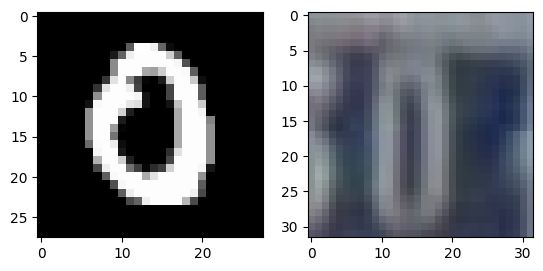

In [7]:
combined = CombinedDataset(mnist, svhn, pairs)

img_mnist, img_svhn, label = combined[1]
print('Label:', label)
plt.subplot(1, 2, 1)
plt.imshow(img_mnist.squeeze(), cmap = 'gray')
plt.subplot(1, 2, 2)
plt.imshow(img_svhn.permute(1,2,0))
plt.show()

In [8]:
img_svhn.max()

tensor(0.6706)

In [9]:
# Initializing the corresponding classes
from Nets import Encoder, Decoder, multiviewVAE
from architecture import (
    mnist_encoder_conv_stack,
    mnist_decoder_conv_stack,
    svhn_decoder_conv_stack,
    svhn_encoder_conv_stack,
    mnist_encoder_linear_stack,
    mnist_decoder_linear_stack,
    svhn_encoder_linear_stack,
    svhn_decoder_linear_stack
    )


latent_dim = 20 # Shared latent space
private_dim_svhn = 4 # Latent just for SVHN
private_dim_mnist = 1 # Less Complex

# Initializing encoder
encoder1 = Encoder(
    latent_dim=latent_dim, 
    private_dim=private_dim_mnist,
    conv_stack = mnist_encoder_conv_stack(),
    linear_stack= mnist_encoder_linear_stack(latent_dim, private_dim_mnist)
)
encoder2 = Encoder(
    latent_dim=latent_dim, 
    private_dim=private_dim_svhn, 
    conv_stack = svhn_encoder_conv_stack(),
    linear_stack= svhn_encoder_linear_stack(latent_dim,private_dim_svhn)
)

# Initializing decoders
# MNIST Decoder
decoder1 = Decoder(
    conv_stack=mnist_decoder_conv_stack(),
    linear_stack=mnist_decoder_linear_stack(latent_dim, private_dim_mnist),
    channels=256,
    height=1,
    width=1,
)

# SVHN Decoder
decoder2 = Decoder(
    conv_stack=svhn_decoder_conv_stack(),
    linear_stack=svhn_decoder_linear_stack(latent_dim, private_dim_svhn),
    channels=256,
    height=1,
    width=1,
)

# Initializing multi-viewVAE
vae = multiviewVAE(
    encoder1=encoder1,
    encoder2=encoder2,
    decoder1=decoder1,
    decoder2=decoder2,
    var_x1=0.08, # May be adjusted depending on if we prioritize KL or not, Lower values provide more importance to detail while reducing KL divergence influence
    var_x2=0.08, # A really low var_x value will completely discard the KL divergence, therefore, reducing generation performance
    private_dim_mnist=private_dim_mnist,
    private_dim_svhn=private_dim_svhn
)


In [10]:
# Train on GPU if possible
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
vae  = vae.to(device)

# Training Loop
dataloader = DataLoader(combined, batch_size=128, shuffle=True)

history = vae.train_loop(dataloader, lr=3e-4, epochs=50, device=device)

Epoch 1 | ELBO loss: -372.051 | LL: 752.572 | Align Loss: 0.312 | KL shared (s1/s2): 0.926/0.626 | KL private (p1/p2): 2.733/3.561
Epoch 2 | ELBO loss: -757.491 | LL: 1532.190 | Align Loss: 0.747 | KL shared (s1/s2): 1.740/0.505 | KL private (p1/p2): 3.520/9.949
Epoch 3 | ELBO loss: -848.688 | LL: 1725.991 | Align Loss: 2.454 | KL shared (s1/s2): 5.108/3.184 | KL private (p1/p2): 3.765/11.649
Epoch 4 | ELBO loss: -881.630 | LL: 1800.659 | Align Loss: 3.274 | KL shared (s1/s2): 8.742/6.509 | KL private (p1/p2): 3.820/11.780
Epoch 5 | ELBO loss: -902.668 | LL: 1846.180 | Align Loss: 2.982 | KL shared (s1/s2): 10.471/8.479 | KL private (p1/p2): 3.968/11.962
Epoch 6 | ELBO loss: -919.057 | LL: 1879.911 | Align Loss: 2.836 | KL shared (s1/s2): 11.004/9.046 | KL private (p1/p2): 4.088/11.985
Epoch 7 | ELBO loss: -928.314 | LL: 1899.143 | Align Loss: 2.806 | KL shared (s1/s2): 11.418/9.259 | KL private (p1/p2): 4.162/12.063
Epoch 8 | ELBO loss: -935.488 | LL: 1914.588 | Align Loss: 2.920 | KL

In [11]:
# Saving model weights and architecture
# Save the full model architecture + weights
os.makedirs("./checkpoints", exist_ok=True)
torch.save(vae, "./checkpoints/multiview_vae.pth")

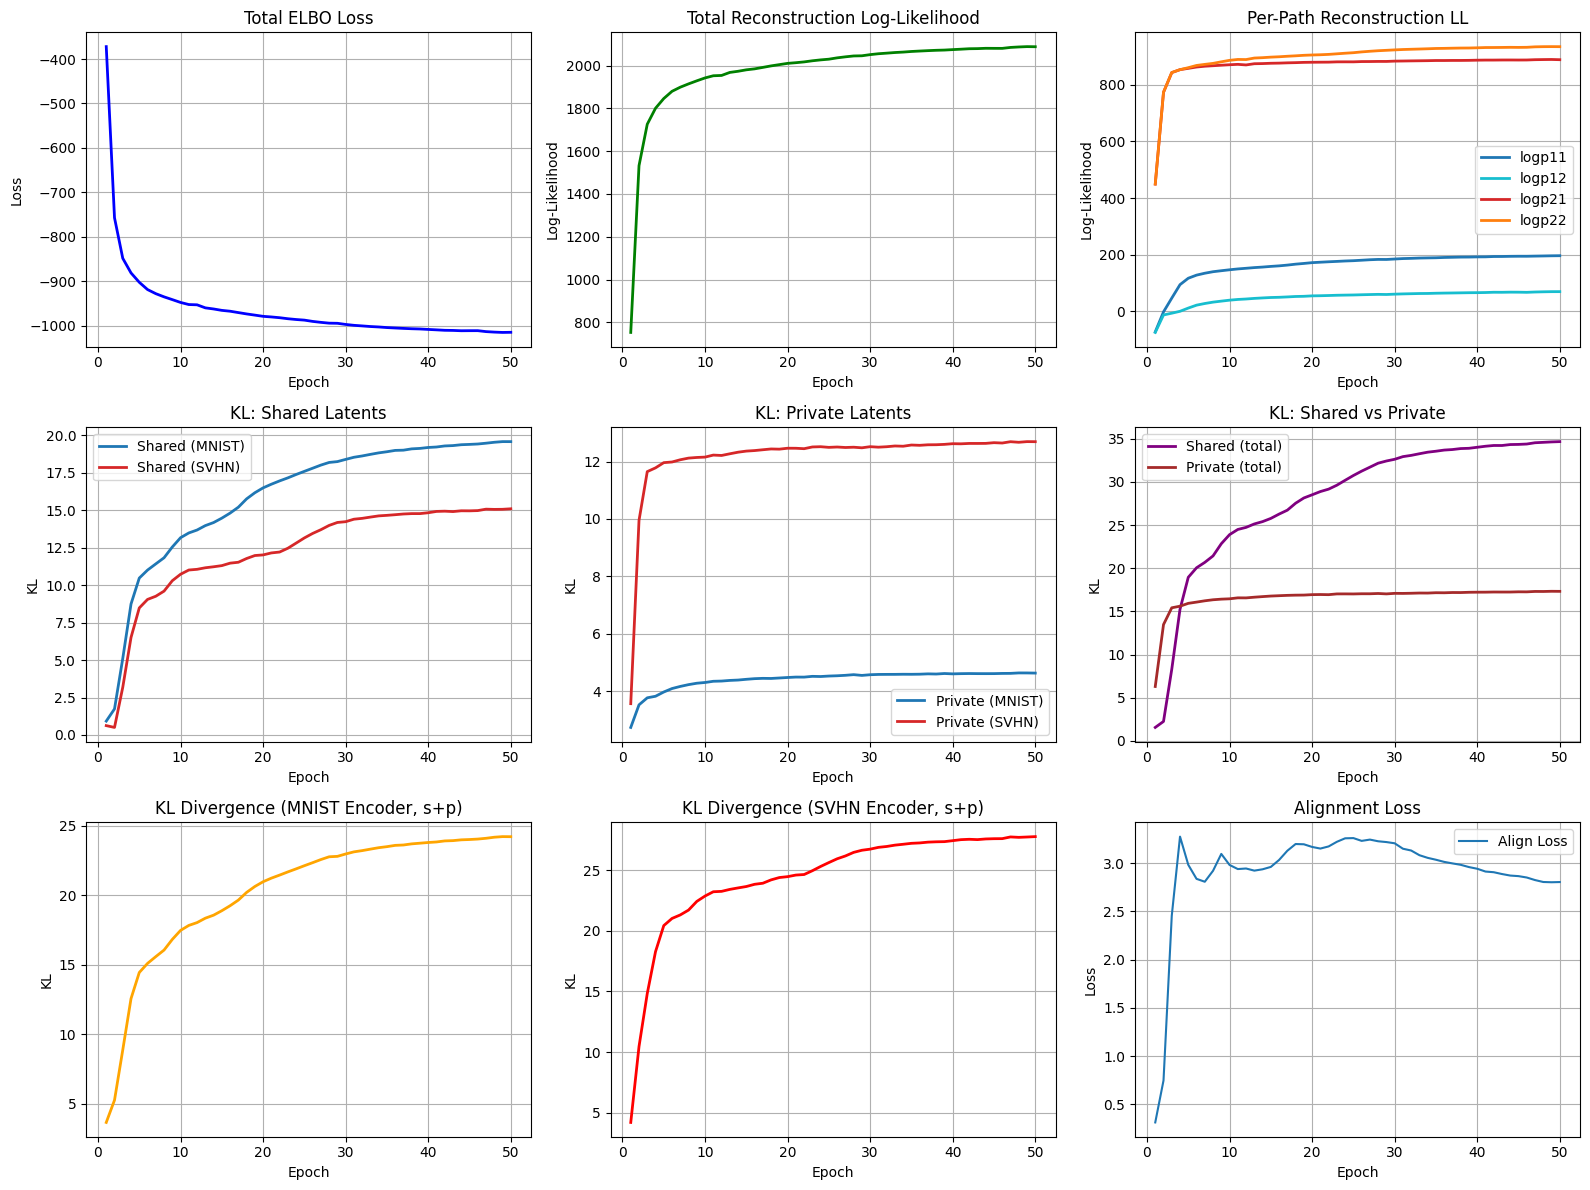

In [12]:
# Plotting training losses
epochs_range = range(1, len(history["elbo"]) + 1)

plt.figure(figsize=(16, 12))

# ELBO loss
plt.subplot(3, 3, 1)
plt.plot(epochs_range, history["elbo"], color="blue", linewidth=2)
plt.title("Total ELBO Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.grid(True)

# Total Reconstruction
plt.subplot(3, 3, 2)
plt.plot(epochs_range, history["rec"], color="green", linewidth=2)
plt.title("Total Reconstruction Log-Likelihood")
plt.xlabel("Epoch"); plt.ylabel("Log-Likelihood"); plt.grid(True)

# Log-likelihoods per path
plt.subplot(3, 3, 3)
for k, c in zip(["logp11", "logp12", "logp21", "logp22"], ["tab:blue", "tab:cyan", "tab:red", "tab:orange"]):
    plt.plot(epochs_range, history[k], label=k, color=c, linewidth=2)
plt.title("Per-Path Reconstruction LL")
plt.xlabel("Epoch"); plt.ylabel("Log-Likelihood"); plt.legend(); plt.grid(True)

# Shared KLs
plt.subplot(3, 3, 4)
plt.plot(epochs_range, history["kl_s1"], label="Shared (MNIST)", color="tab:blue", linewidth=2)
plt.plot(epochs_range, history["kl_s2"], label="Shared (SVHN)", color="tab:red", linewidth=2)
plt.title("KL: Shared Latents")
plt.xlabel("Epoch"); plt.ylabel("KL"); plt.legend(); plt.grid(True)

# Private KLs
plt.subplot(3, 3, 5)
plt.plot(epochs_range, history["kl_p1"], label="Private (MNIST)", color="tab:blue", linewidth=2)
plt.plot(epochs_range, history["kl_p2"], label="Private (SVHN)", color="tab:red", linewidth=2)
plt.title("KL: Private Latents")
plt.xlabel("Epoch"); plt.ylabel("KL"); plt.legend(); plt.grid(True)

# Shared vs private totals
plt.subplot(3, 3, 6)
plt.plot(epochs_range, history["kl_shared"], label="Shared (total)", color="purple", linewidth=2)
plt.plot(epochs_range, history["kl_private"], label="Private (total)", color="brown", linewidth=2)
plt.title("KL: Shared vs Private")
plt.xlabel("Epoch"); plt.ylabel("KL"); plt.legend(); plt.grid(True)

# KL Totals
plt.subplot(3, 3, 7)
plt.plot(epochs_range, history["kl1"], color="orange", linewidth=2)
plt.title("KL Divergence (MNIST Encoder, s+p)")
plt.xlabel("Epoch"); plt.ylabel("KL"); plt.grid(True)

plt.subplot(3, 3, 8)
plt.plot(epochs_range, history["kl2"], color="red", linewidth=2)
plt.title("KL Divergence (SVHN Encoder, s+p)")
plt.xlabel("Epoch"); plt.ylabel("KL"); plt.grid(True)

# Align Loss
plt.subplot(3,3,9)
plt.plot(epochs_range, history["align"], label="Align Loss")
plt.title("Alignment Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.grid(True)

plt.tight_layout()
plt.show()

In [15]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vae = torch.load("./checkpoints/multiview_vae_full.pth", map_location=device, weights_only=False)
vae = vae.to(device)

additional_epochs = 30
history_cont = vae.train_loop(dataloader, lr=1e-4, epochs=additional_epochs, device=device)

torch.save(vae, "./checkpoints/multiview_vae_full_epoch50.pth")

Epoch 1 | ELBO loss: -594.156 | LL: 1229.520 | Align Loss: 2.317 | KL shared (s1/s2): 12.832/9.276 | KL private (p1/p2): 4.464/10.001
Epoch 2 | ELBO loss: -594.750 | LL: 1231.042 | Align Loss: 2.323 | KL shared (s1/s2): 12.983/9.361 | KL private (p1/p2): 4.514/10.039
Epoch 3 | ELBO loss: -596.388 | LL: 1234.468 | Align Loss: 2.300 | KL shared (s1/s2): 13.070/9.449 | KL private (p1/p2): 4.510/10.062
Epoch 4 | ELBO loss: -597.358 | LL: 1236.558 | Align Loss: 2.316 | KL shared (s1/s2): 13.131/9.511 | KL private (p1/p2): 4.505/10.063
Epoch 5 | ELBO loss: -598.413 | LL: 1238.896 | Align Loss: 2.313 | KL shared (s1/s2): 13.211/9.619 | KL private (p1/p2): 4.529/10.085
Epoch 6 | ELBO loss: -599.284 | LL: 1240.866 | Align Loss: 2.350 | KL shared (s1/s2): 13.282/9.657 | KL private (p1/p2): 4.537/10.121
Epoch 7 | ELBO loss: -599.951 | LL: 1242.466 | Align Loss: 2.357 | KL shared (s1/s2): 13.395/9.818 | KL private (p1/p2): 4.538/10.099
Epoch 8 | ELBO loss: -600.974 | LL: 1244.666 | Align Loss: 2.3